In [1]:
import torch
import hornbill
import numpy as np
import matplotlib.pyplot as plt

## Optimising the parameters

The parameters $\vec p = (p_x, p_y, p_z)$ define a Hamiltonian $\mathcal{H}(\vec p) = p_x X + p_y Y + p_z Z$, which generates the unitary $U(\vec p) = e^{-i t \mathcal{H}(\vec p)}$. We want $U(\vec p)$ to equal the target $H$ (Hadamard) up to a global phase.

The loss is the infidelity $1 - |\mathrm{Tr}(H^\dagger U)/d|^2$. It is zero exactly when $U = e^{i\phi} H$ and is smooth, so autograd gives its gradient with respect to $\vec p$ through `torch.matrix_exp`. Plain gradient descent then updates $\vec p \leftarrow \vec p - \eta\, \nabla_{\vec p}\,\mathrm{loss}$.

In [2]:
sigmas = [hornbill.operators.X, hornbill.operators.Y, hornbill.operators.Z]
t = 1.0
target = hornbill.operators.H

def create_unitary(params):
    ham = sum(p_i * s_i for p_i, s_i in zip(params, sigmas))
    return hornbill.time_evolution(ham, t)

def loss(params):
    return hornbill.unitary_infidelity(target, create_unitary(params))

In [3]:
params = torch.rand(3, requires_grad=True)
history = hornbill.gradient_descent(loss, [params], lr=0.5, steps=1000, tol=1e-12)
print(f"Stopped after {len(history)} steps\nInitial infidelity: {history[0]:.2e}\nFinal infidelity {history[-1]:.2e}")

Stopped after 29 steps
Initial infidelity: 7.66e-01
Final infidelity 4.08e-13


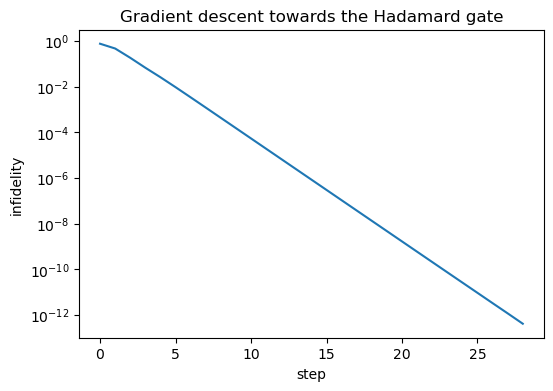

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(history)
ax.set_xlabel("step")
ax.set_ylabel("infidelity")
ax.set_title("Gradient descent towards the Hadamard gate")
plt.show()

In [5]:
final = create_unitary(params).detach()
print("optimised params:", params.detach())
print("unitary distance to target:", hornbill.unitary_distance(target, final).item())

# The optimised unitary matches H only up to a global phase e^{i phi}.
# Tr(H^dagger U) = d e^{i phi}, so divide that phase out before comparing entries.
overlap = torch.trace(target.conj().T @ final)
global_phase = overlap / overlap.abs()
print("\nglobal phase:", np.round(global_phase.item(), 6))
print("U / phase:\n", np.round((final / global_phase).numpy(), 6))
print("target H:\n", np.round(target.numpy(), 6))

optimised params: tensor([1.1107e+00, 5.8654e-07, 1.1107e+00])
unitary distance to target: 2.7028258364226004e-07

global phase: -1j
U / phase:
 [[ 0.707107+0.j  0.707107-0.j]
 [ 0.707107+0.j -0.707107+0.j]]
target H:
 [[ 0.707107+0.j  0.707107+0.j]
 [ 0.707107+0.j -0.707107+0.j]]


## Check against the analytic solution

For a unit vector $\hat n$, $e^{-i\theta\,\hat n\cdot\vec\sigma} = \cos\theta\, I - i \sin\theta\, \hat n\cdot\vec\sigma$. Since $H = (X + Z)/\sqrt{2}$, choosing $\hat n = (1, 0, 1)/\sqrt{2}$ and $\theta = \pi/2$ gives

$$e^{-i\frac{\pi}{2}\hat n\cdot\vec\sigma} = -iH,$$

which equals $H$ up to a global phase. With $t = 1$ the parameters are $\vec p = \theta\,\hat n = \frac{\pi}{2\sqrt{2}}(1, 0, 1) \approx (1.1107, 0, 1.1107)$.

This is not the only solution: $-\vec p$ also works, as does $\theta = \pi/2 + k\pi$ for any integer $k$. Starting from `torch.rand` (all entries in $[0, 1)$), gradient descent reaches the one above.

In [6]:
expected = torch.tensor([1.0, 0.0, 1.0], dtype=torch.float64) * np.pi / (2 * np.sqrt(2))
print("expected:", expected)
print("found:   ", params.detach())

expected: tensor([1.1107, 0.0000, 1.1107], dtype=torch.float64)
found:    tensor([1.1107e+00, 5.8654e-07, 1.1107e+00])
